In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


PLUMBER_ROOT = Path("/glade/work/bbuchovecky/data/fluxnet_abramowitz")
L_V = 2.45e6
SEC_PER_YEAR = 86400 * 365.25
MIN_YEAR_THRESH = 3

In [2]:
inputs = xr.open_dataset("/glade/work/bbuchovecky/et_unc/proc/plumber/inputs/199501-201412/plumber.inputs.1deg.199501-201412.nc")

In [26]:
inputs

<xarray.Dataset> Size: 39kB
Dimensions:         (member: 167, year: 20, lai_pr_rn: 1)
Coordinates: (12/16)
  * member          (member) <U6 4kB 'AR-SLu' 'AT-Neu' ... 'ZA-Kru' 'ZM-Mon'
    grid_lat        (member) float64 1kB ...
    grid_lon        (member) float64 1kB ...
    lat             (member) float64 1kB ...
    lon             (member) float64 1kB ...
    n_years         (member) int64 1kB ...
    ...              ...
    obs_source      (lai_pr_rn) <U38 152B ...
    lai_product     (lai_pr_rn) <U11 44B ...
    pr_product      (lai_pr_rn) <U8 32B ...
    rn_product      (lai_pr_rn) <U9 36B ...
    clim_n_years    (lai_pr_rn) int64 8B ...
    clim_period     (lai_pr_rn) <U13 52B ...
Data variables:
    et              (member, year) float32 13kB ...
    lai             (lai_pr_rn, member) float64 1kB ...
    pr              (lai_pr_rn, member) float64 1kB ...
    rn              (lai_pr_rn, member) float64 1kB ...
    ai              (lai_pr_rn, member) float64 1kB ...
Attributes:
    family:         plumber
    dataset:        PLUMBER2 flux towers: tower ET, obs LAI/P/Rn/AI at the ne...
    time_period:    199501-201412
    grid:           1deg
    plumber_root:   /glade/work/bbuchovecky/data/fluxnet_abramowitz
    obs_inputs:     /glade/derecho/scratch/bbuchovecky/et_unc/proc/obs/obs.in...
    min_annual_et:  -2.0

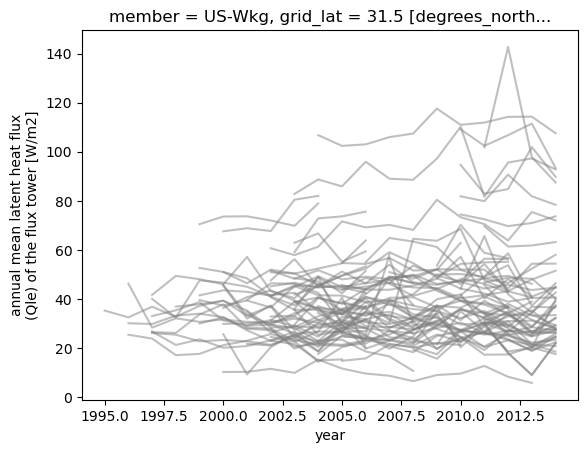

In [25]:
for m in inputs.member:
    x = inputs.et.sel(member=m)
    if (x.mean() > 0) and ((~np.isnan(x)).sum() > 3):
        x.plot(color="gray", alpha=0.5)

In [4]:
def time_range(da):
    t = da.time
    return f"{t[0].dt.strftime('%Y-%m-%d').item()} - {t[-1].dt.strftime('%Y-%m-%d').item()}"

In [ ]:
met = {}
for f in sorted((PLUMBER_ROOT / "met").iterdir()):
    key = f.stem.split("_")[0]
    met[key] = xr.open_dataset(f)

flux = {}
for f in sorted((PLUMBER_ROOT / "flux").iterdir()):
    key = f.stem.split("_")[0]
    flux[key] = xr.open_dataset(f)

In [ ]:
rows = []
for site, s_met in met.items():
    m, fl = s_met, flux[site]
    n_days = (m.time[-1] - m.time[0]).values / np.timedelta64(1, "D")
    rows.append({
        "site": site,
        "pr": m["Precip"].mean().item() * SEC_PER_YEAR,             # kg m-2 s-1 -> mm/yr
        "tas": m["Tair"].mean().item() - 273.15,                    # K -> degC
        "et": fl["Qle"].mean().item() / L_V * SEC_PER_YEAR,         # W m-2 -> mm/yr
        "n_years": n_days / 365.25,
    })
sites = pd.DataFrame(rows).set_index("site")

sites_filt = sites[sites.n_years >= MIN_YEAR_THRESH]

In [42]:
sites.describe()

,pr,tas,et,n_years
count,170.000000,170.000000,170.000000,170.000000
mean,850.394285,11.450401,511.460470,6.117748
std,780.565262,7.607861,260.617735,4.768937
min,53.884882,-8.862036,100.564764,0.999258
25%,485.233897,6.551645,338.019074,2.001312
50%,703.033668,10.579691,455.132140,4.499601
75%,977.381921,16.335878,609.841426,8.999258
max,7894.795333,27.270135,1407.543603,21.001939


In [43]:
sites_filt.describe()

,pr,tas,et,n_years
count,120.000000,120.000000,120.000000,120.000000
mean,899.007641,11.609039,520.938251,7.941805
std,868.938109,7.491517,254.630395,4.558142
min,147.389382,-8.862036,106.412500,3.000627
25%,529.531416,6.989526,337.047285,3.999943
50%,763.396074,10.344568,463.026222,7.000627
75%,980.244778,16.424371,617.251865,10.251127
max,7894.795333,27.270135,1407.543603,21.001939


(-100.0, 4500.0)

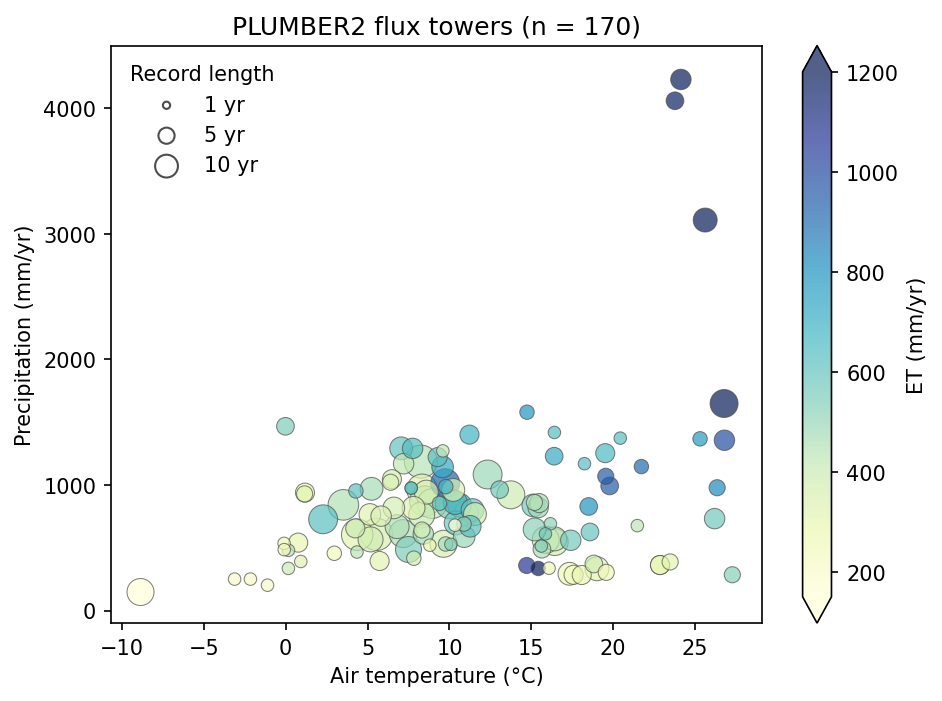

In [45]:
# Long records drawn first so the short ones stay visible on top
s = sites_filt.sort_values("n_years", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5),dpi=150)
sc = ax.scatter(
    s["tas"], s["pr"], c=s["et"], s=12 * s["n_years"],  # marker area ∝ record length
    cmap="YlGnBu", edgecolor="0.3", alpha=0.7, linewidth=0.5, vmin=150, vmax=1200, 
)
fig.colorbar(sc, ax=ax, extend="both", label="ET (mm/yr)")

# Size legend for the record length
for n in (1, 5, 10):
    ax.scatter([], [], s=12 * n, c="none", edgecolor="0.3", label=f"{n} yr")
ax.legend(title="Record length", loc="upper left", frameon=False)

ax.set_ylabel("Precipitation (mm/yr)")
ax.set_xlabel("Air temperature (°C)")
ax.set_title(f"PLUMBER2 flux towers (n = {len(sites)})")

ax.set_ylim(-100, 4500)

4 sites outside the edges, clipped into the edge bins


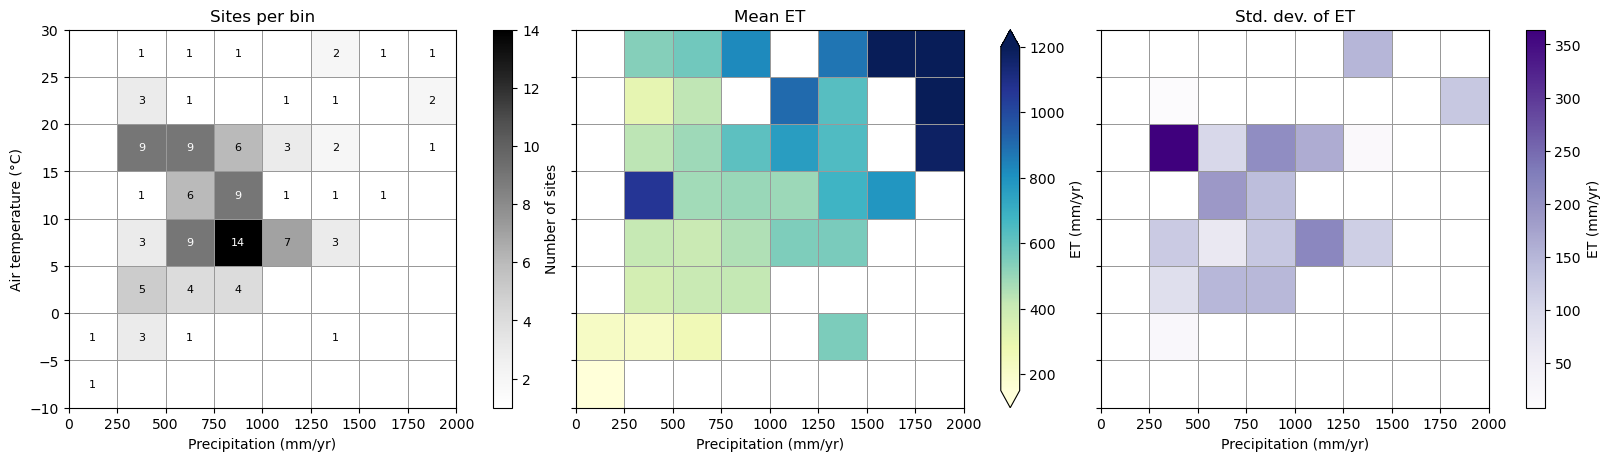

In [ ]:
P_EDGES = np.arange(0, 2001, 250)   # precipitation bin edges (mm/yr)
T_EDGES = np.arange(-10, 31, 5)     # temperature bin edges (degC)

# Bin index of each site; values outside the edges are clipped into the edge bins
ix = np.clip(np.searchsorted(P_EDGES, sites_filt["pr"], side="right") - 1, 0, len(P_EDGES) - 2)
iy = np.clip(np.searchsorted(T_EDGES, sites_filt["tas"], side="right") - 1, 0, len(T_EDGES) - 2)
n_clipped = ((sites_filt["pr"] >= P_EDGES[-1]) | (sites_filt["tas"] < T_EDGES[0]) | (sites_filt["tas"] >= T_EDGES[-1])).sum()
print(f"{n_clipped} sites outside the edges, clipped into the edge bins")

# ET statistics of the sites in each (T, P) bin; empty bins stay NaN
et_by_bin = sites_filt["et"].groupby([iy, ix])
bin_stats = {
    "count": et_by_bin.count(),
    "mean": et_by_bin.mean(),
    "std": et_by_bin.std(),         # sample std (ddof=1), NaN for single-site bins
}

def to_grid(series):
    grid = np.full((len(T_EDGES) - 1, len(P_EDGES) - 1), np.nan)
    grid[series.index.get_level_values(0), series.index.get_level_values(1)] = series.values
    return grid

# (stat, title, cmap, colorbar label, color range); mean ET uses the scatter plot's color range
panels = [
    ("count", "Sites per bin", "Greys", "Number of sites", {}),
    ("mean", "Mean ET", "YlGnBu", "ET (mm/yr)", {"vmin": 150, "vmax": 1200}),
    ("std", "Std. dev. of ET", "Purples", "ET (mm/yr)", {}),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, layout="constrained")
for ax, (stat, title, cmap, label, crange) in zip(axes, panels):
    pc = ax.pcolormesh(P_EDGES, T_EDGES, to_grid(bin_stats[stat]), cmap=cmap,
                       edgecolor="0.6", linewidth=0.5, **crange)
    fig.colorbar(pc, ax=ax, label=label, extend="both" if crange else "neither")
    ax.set_title(title)
    ax.set_xlabel("Precipitation (mm/yr)")
axes[0].set_ylabel("Air temperature (°C)")

# Write the number of sites in each non-empty bin
P_MID, T_MID = (P_EDGES[:-1] + P_EDGES[1:]) / 2, (T_EDGES[:-1] + T_EDGES[1:]) / 2
for (j, i), n in bin_stats["count"].items():
    axes[0].text(P_MID[i], T_MID[j], n, ha="center", va="center", fontsize=8,
                 color="w" if n > bin_stats["count"].max() / 2 else "k")